# 2.11. Мета-лернеры (Meta-learners)

**План занятия**

1. S-learner, T-learner и X-learner.
2. Сравнение мета-лернеров на данных и на симуляции с известным эффектом.
3. Double/Debiased ML: теорема Фриша — Во — Ловелла и ML.
4. CATE и R-learner.
5. Что на самом деле оценивает непараметрический Double ML.
6. Контрфактические прогнозы и их проверка.

### Библиотеки

Кроме стандартного набора нужен `lightgbm`. В Colab его можно поставить командой `!pip install -q lightgbm`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from ipywidgets import FloatSlider, interact
from lightgbm import LGBMRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE = '#8172B3'
DATA = 'data/'
rng = np.random.default_rng(42)


def effect_slope(df, y, t):
    """Считает наклон регрессии y на t, ноль если воздействие внутри группы не меняется."""
    spread = np.sum((df[t] - df[t].mean()) ** 2)
    return np.sum((df[t] - df[t].mean()) * (df[y] - df[y].mean())) / spread if spread > 0 else 0.0


def cumulative_gain(dataset, prediction, y, t, min_periods=30, steps=100):
    """Строит кривую кумулятивного прироста при сортировке по оценке CATE."""
    size = dataset.shape[0]
    ordered = dataset.sort_values(prediction, ascending=False).reset_index(drop=True)
    n_rows = list(range(min_periods, size, size // steps)) + [size]
    return np.array(n_rows) / size * 100, np.array([effect_slope(ordered.head(rows), y, t) * (rows / size) for rows in n_rows])


def plot_gain(ax, curves, baseline, title):
    for (share, gain), color, label in curves:
        ax.plot(share, gain, color=color, lw=2.5, label=label)
    ax.plot([0, 100], [0, baseline], ls='--', color='black', label='Случайный порядок')
    ax.set_xlabel('Доля выборки, %')
    ax.set_ylabel('Кумулятивный прирост')
    ax.set_title(title, fontsize=12)
    ax.legend()


def gain_area(curve, baseline):
    """Считает площадь между кривой и случайным порядком в долях среднего эффекта."""
    share, gain = curve
    return float(np.trapezoid(gain - baseline * share / 100, share)) / 100 / abs(baseline)

## Мета-лернеры

Нас интересует неоднородность эффекта:

$$
\tau(x) = E[Y_i(1) - Y_i(0)|X] = E[\tau_i|X]
$$

или производная исхода по воздействию в непрерывном случае. Это полезно, когда нельзя воздействовать на всех и нужно расставить приоритеты: например, бюджет на скидки ограничен.

В лекции 2.10 мы преобразовывали цель и платили за это большой дисперсией. **Мета-лернеры** — это другой способ использовать готовые ML-модели для оценки CATE. Базовой моделью может быть что угодно: от линейной регрессии до нейросети, и успех во многом зависит от этого выбора.

Используем те же письма об инвестициях. На этот раз для обучения берём **неслучайные** данные, а для проверки — случайные. Это гораздо сложнее: алгоритм должен и устранить смещение, и оценить CATE.

In [2]:
test = pd.read_csv(DATA + 'invest_email_rnd.csv')
train = pd.read_csv(DATA + 'invest_email_biased.csv')

outcome = 'converted'
treatment = 'em1'
features = ['age', 'income', 'insurance', 'invested']
effect_rnd = effect_slope(test, outcome, treatment)

print(f'Эффект на случайных данных:     {effect_rnd:.3f}')
print(f'Разница на смещённых данных:    {effect_slope(train, outcome, treatment):.3f}')
print(f'Доля получивших письмо на смещённых данных: {train[treatment].mean():.3f}')
train[features + [treatment]].corr()[treatment].round(3).drop(treatment)

Эффект на случайных данных:     0.069
Разница на смещённых данных:    0.048
Доля получивших письмо на смещённых данных: 0.225


age         -0.034
income      -0.315
insurance   -0.005
invested    -0.254
Name: em1, dtype: float64

### S-Learner

S-learner — самый простой алгоритм. Используем одну (single) ML-модель $M_s$ и включаем воздействие как обычный признак:

$$
\mu(x) = E[Y| T, X]
$$

Разница прогнозов при разных значениях воздействия даёт оценку CATE:

$$
\hat{\tau}(x)_i = M_s(X_i, T=1) - M_s(X_i, T=0)
$$

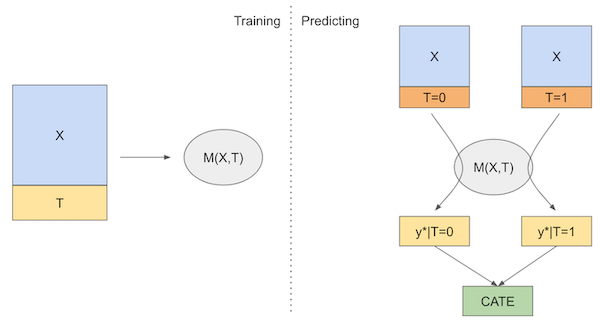

Обучим модель и посмотрим на кривую прироста на случайных данных. На смещённой обучающей выборке кривая не показывает качество, но помогает заметить переобучение. Чтобы увидеть его, увеличьте `max_depth` с 3 до 20.

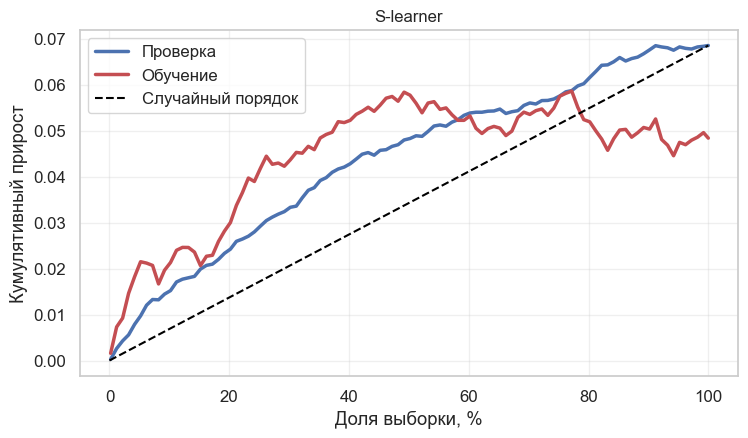

In [3]:
params_s = dict(max_depth=3, min_child_samples=30, verbose=-1, random_state=123)
s_learner = LGBMRegressor(**params_s).fit(train[features + [treatment]], train[outcome])


def s_predict(data):
    return (s_learner.predict(data[features].assign(**{treatment: 1})) -
            s_learner.predict(data[features].assign(**{treatment: 0})))


s_test = test.assign(cate=s_predict(test))
s_train = train.assign(cate=s_predict(train))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_gain(ax, [(cumulative_gain(s_test, 'cate', outcome, treatment), BLUE, 'Проверка'),
               (cumulative_gain(s_train, 'cate', outcome, treatment), RED, 'Обучение')], effect_rnd, 'S-learner');

Несмотря на простоту, S-learner хорошо работает на этом наборе. Это удачный первый выбор: он прост и работает и с дискретным, и с непрерывным воздействием, а многие другие алгоритмы только с дискретным.

Главный недостаток — **эффект сдвигается к нулю**. S-learner обычно использует регуляризованную модель, и регуляризация сжимает оценку эффекта. Чернозуков и соавторы (2016) показывают это на симуляции:

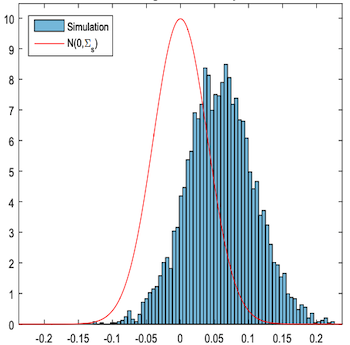

Здесь показано распределение разницы $\hat{\tau} - \tau$: красным контуром — истинное положение, рядом — оценка S-learner, которая заметно смещена.

Если воздействие очень слабое по сравнению с другими признаками, модель может вообще отбросить его. Чем сильнее регуляризация, тем серьёзнее проблема.

### T-Learner

T-learner решает проблему отбрасывания воздействия, обучая отдельную модель для каждого значения воздействия. В бинарном случае их две (two):

$$
\mu_0(x) = E[Y| T=0, X], \qquad \mu_1(x) = E[Y| T=1, X]
$$

CATE равен разности прогнозов:

$$
\hat{\tau}(x)_i = M_1(X_i) - M_0(X_i)
$$

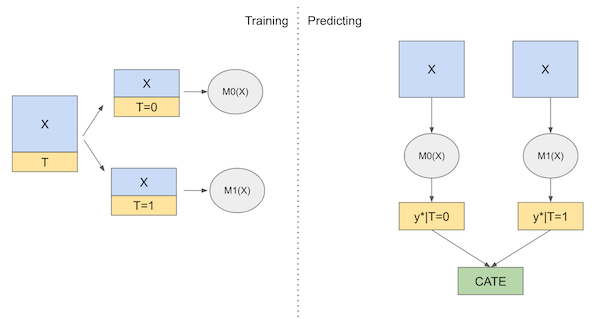

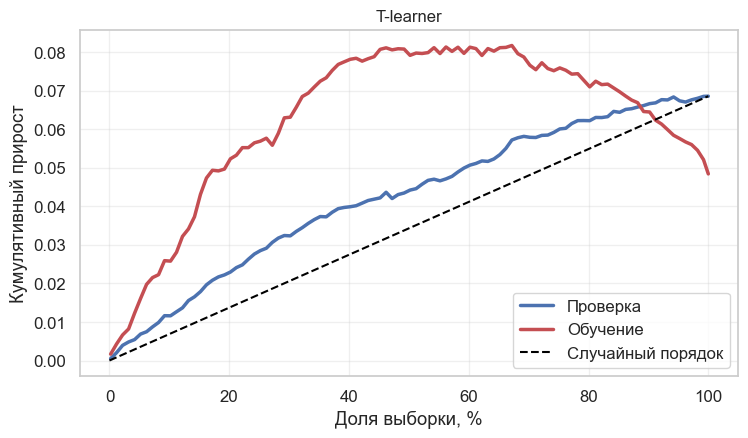

In [4]:
params_t = dict(max_depth=2, min_child_samples=60, verbose=-1, random_state=123)
m0 = LGBMRegressor(**params_t).fit(train.query(f'{treatment} == 0')[features], train.query(f'{treatment} == 0')[outcome])
m1 = LGBMRegressor(**params_t).fit(train.query(f'{treatment} == 1')[features], train.query(f'{treatment} == 1')[outcome])

t_test = test.assign(cate=m1.predict(test[features]) - m0.predict(test[features]))
t_train = train.assign(cate=m1.predict(train[features]) - m0.predict(train[features]))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_gain(ax, [(cumulative_gain(t_test, 'cate', outcome, treatment), BLUE, 'Проверка'),
               (cumulative_gain(t_train, 'cate', outcome, treatment), RED, 'Обучение')], effect_rnd, 'T-learner');

На проверке T-learner близок к S-learner, а на обучении заметно лучше. Это признак переобучения: каждая модель видит только часть данных. Сравнение по площади будет ниже.

T-learner избегает отбрасывания воздействия, но страдает от другого вида смещения из-за регуляризации. Рассмотрим ситуацию из работы Кюнцеля и соавторов (2019). Данных контрольной группы много, тестовой мало, что часто бывает, потому что воздействие стоит дорого. Пусть зависимость $Y$ от $X$ нелинейна, а **эффект постоянен**.

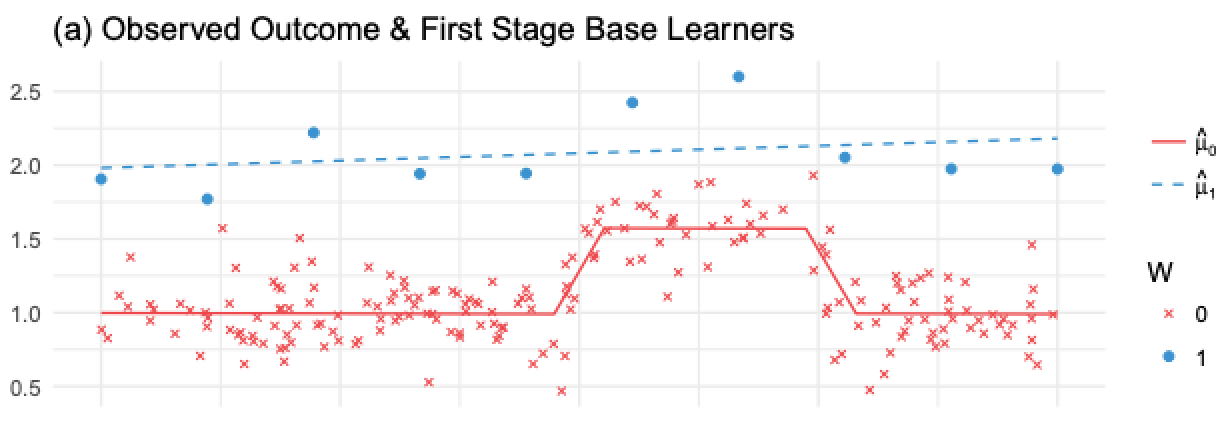

Из-за малого числа тестовых наблюдений $M_1$ будет простой моделью (здесь линейной), чтобы не переобучиться. $M_0$ будет сложнее, данных для этого достаточно. Но разность $\hat{\tau}=M_1(X) - M_0(X)$, то есть линейная функция минус нелинейная, даст нелинейный CATE, хотя настоящий постоянен и равен 1.

Модель контрольной группы уловила нелинейность, а тестовая нет. Меньше регуляризации — значит переобучение на малой выборке. Решение предложено в той же статье.

### X-Learner

X-learner устроен сложнее, но реализуется просто. Он состоит из двух этапов и модели propensity score. Первый этап как у T-learner:

$$
\hat{M}_0(X) \approx E[Y| T=0, X], \qquad \hat{M}_1(X) \approx E[Y| T=1, X]
$$

На втором этапе **вменяем индивидуальные эффекты**. Для контрольных объектов берём прогноз чужой модели минус факт, а для тестовых наоборот:

$$
\hat{\tau}_i = \hat{M}_1(X_i) - Y_i \text{ при } T_i=0, \qquad \hat{\tau}_i = Y_i - \hat{M}_0(X_i) \text{ при } T_i=1
$$

Затем обучаем две модели предсказывать эти эффекты:

$$
\hat{M}_{\tau 0}(X) \approx E[\hat{\tau}|X, T=0], \qquad \hat{M}_{\tau 1}(X) \approx E[\hat{\tau}|X, T=1]
$$

На картинке вменённые эффекты контрольной группы показаны красными крестиками, а $\hat{M}_{\tau 0}$ красным пунктиром. Эта модель неверна: крестики получены с простой моделью $\hat{M}_1$, которая не видит нелинейность $Y$.

Синие точки — эффекты тестовых объектов. Они посчитаны по хорошей модели $M_0$, обученной на большой контрольной выборке, поэтому верны, и модель $\hat{M}_{\tau 1}$ (синяя линия) тоже.

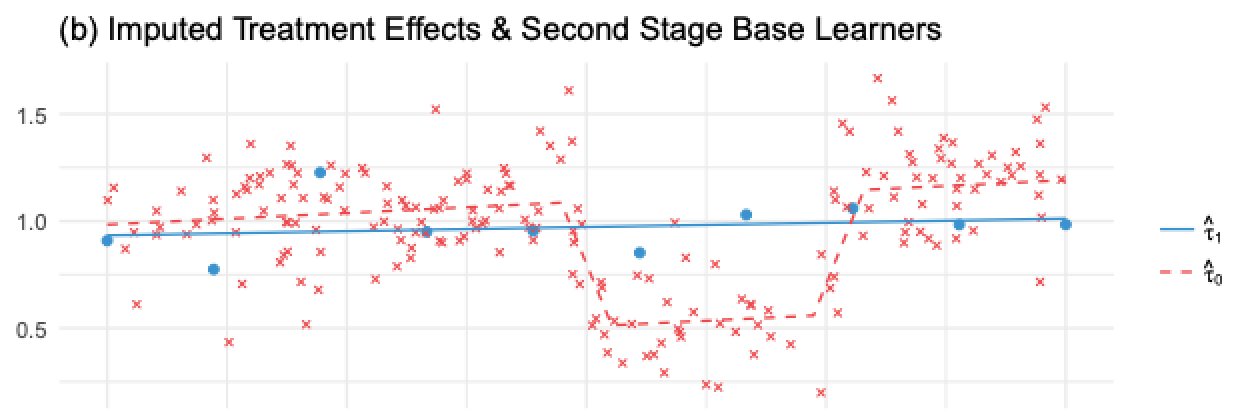

Значит, одна модель неверна, другая верна, и нужно дать вес верной. Для этого используем propensity score:

$$
\hat{\tau}(x) = \hat{M}_{\tau 0}(X)\hat{e}(x) + \hat{M}_{\tau 1}(X)(1-\hat{e}(x))
$$

Тестовых объектов очень мало, поэтому $\hat{e}(x)$ мало, и неверная модель $\hat{M}_{\tau 0}$ получает маленький вес. Верная $\hat{M}_{\tau 1}$ получает почти весь вес. Иными словами, мы больше доверяем модели, построенной на импутации, где другая группа была большой.

На следующем изображении сравниваются CATE, полученные X-learner и T-learner.

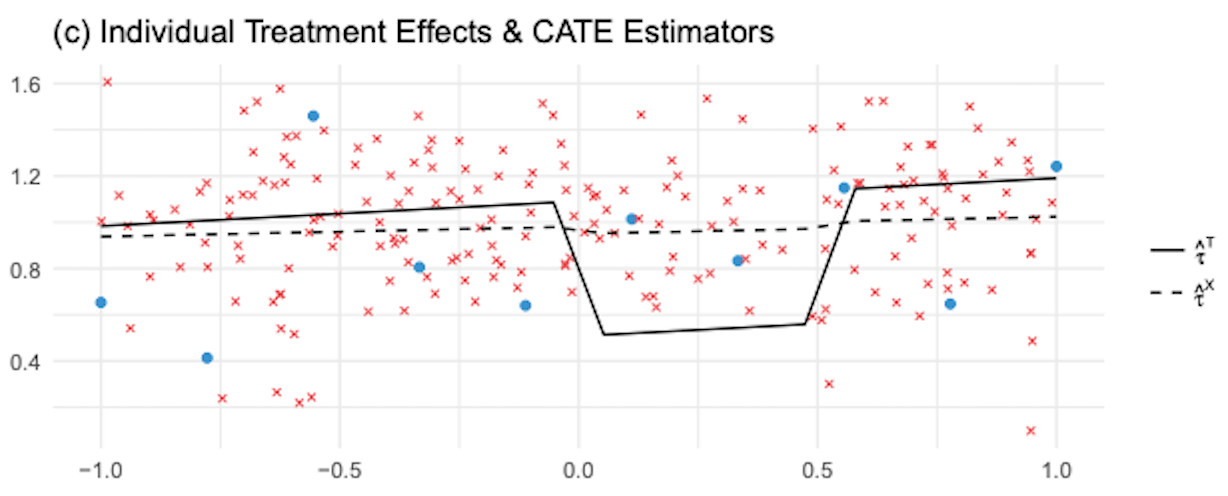

X-learner гораздо лучше исправляет ошибочную нелинейность. Схема алгоритма:

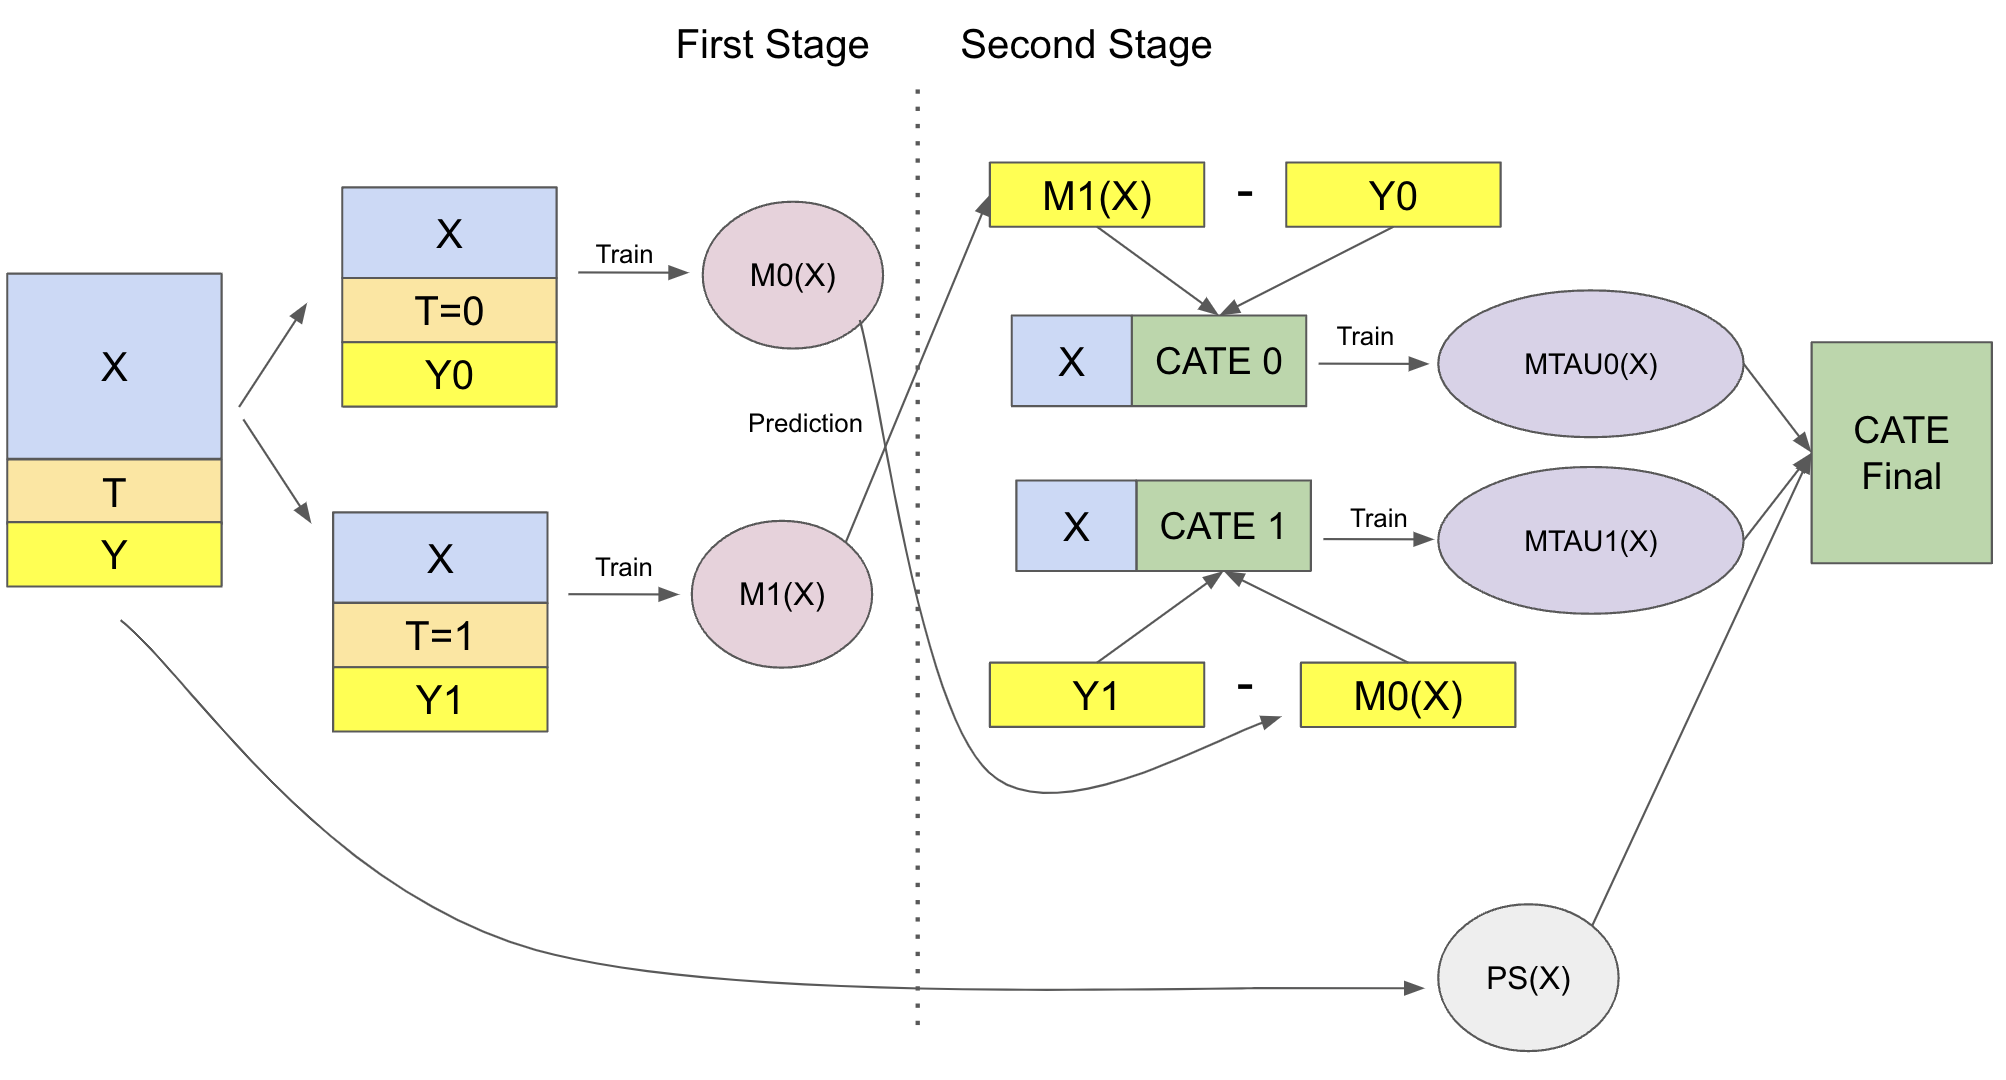

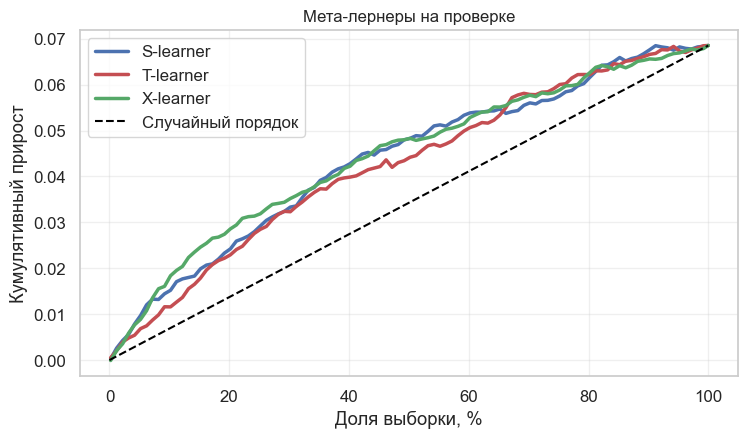

,Средний CATE на проверке,Площадь над случайным порядком
S-learner,0.087,0.138
T-learner,0.095,0.118
X-learner,0.099,0.148


In [5]:
params_x = dict(max_depth=2, min_child_samples=30, verbose=-1, random_state=123)
treated = train[treatment] == 1

m0 = LGBMRegressor(**params_x).fit(train.loc[~treated, features], train.loc[~treated, outcome])
m1 = LGBMRegressor(**params_x).fit(train.loc[treated, features], train.loc[treated, outcome])
propensity = make_pipeline(StandardScaler(), LogisticRegression()).fit(train[features], train[treatment])

imputed = np.where(treated, train[outcome] - m0.predict(train[features]), m1.predict(train[features]) - train[outcome])
mx0 = LGBMRegressor(**params_x).fit(train.loc[~treated, features], imputed[~treated])
mx1 = LGBMRegressor(**params_x).fit(train.loc[treated, features], imputed[treated])


def x_predict(data):
    e = propensity.predict_proba(data[features])[:, 1]
    return e * mx0.predict(data[features]) + (1 - e) * mx1.predict(data[features])


x_test = test.assign(cate=x_predict(test))
x_train = train.assign(cate=x_predict(train))

curves = {'S-learner': (cumulative_gain(s_test, 'cate', outcome, treatment), BLUE),
          'T-learner': (cumulative_gain(t_test, 'cate', outcome, treatment), RED),
          'X-learner': (cumulative_gain(x_test, 'cate', outcome, treatment), GREEN)}

fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_gain(ax, [(curve, color, name) for name, (curve, color) in curves.items()], effect_rnd, 'Мета-лернеры на проверке')
plt.show()

pd.DataFrame({'Средний CATE на проверке': [s_test['cate'].mean(), t_test['cate'].mean(), x_test['cate'].mean()],
              'Площадь над случайным порядком': [gain_area(curve, effect_rnd) for curve, _ in curves.values()]},
             index=list(curves)).round(3)

Все три алгоритма упорядочивают клиентов лучше случайного: площадь от 0.12 до 0.15 среднего эффекта, у X-learner она наибольшая. Разница небольшая и может измениться с базовой моделью или гиперпараметрами. Средний CATE везде завышен: 0.09–0.10 при настоящих 0.069. Значит, смещение не устранено полностью, поэтому такие оценки лучше использовать для ранжирования, а не как величину эффекта.

На реальных данных истина неизвестна, поэтому проверим теорию на симуляции со случая Кюнцеля: нелинейный базовый исход, постоянный эффект 1 и малая доля теста. Подвигайте долю тестовых наблюдений.

In [6]:
def fit_learners(share, n=4000, seed=3):
    """Оценивает S, T и X на данных с постоянным эффектом 1 и заданной долей теста."""
    local = np.random.default_rng(seed)
    x = local.uniform(-3, 3, n).reshape(-1, 1)
    t = (local.random(n) < share).astype(int)
    y = 3 * np.sin(x[:, 0] * 1.5) + t + local.normal(0, 0.5, n)
    grid = np.linspace(-3, 3, 200).reshape(-1, 1)

    small = dict(n_estimators=60, max_depth=2, min_child_samples=50, verbose=-1, random_state=0)
    big = dict(n_estimators=150, max_depth=4, min_child_samples=20, verbose=-1, random_state=0)
    mu0 = LGBMRegressor(**big).fit(x[t == 0], y[t == 0])
    mu1 = LGBMRegressor(**small).fit(x[t == 1], y[t == 1])
    t_cate = mu1.predict(grid) - mu0.predict(grid)

    s_model = LGBMRegressor(**big).fit(np.column_stack([x, t]), y)
    s_cate = s_model.predict(np.column_stack([grid, np.ones(len(grid))])) - s_model.predict(np.column_stack([grid, np.zeros(len(grid))]))

    effect_0 = LGBMRegressor(**small).fit(x[t == 0], mu1.predict(x[t == 0]) - y[t == 0])
    effect_1 = LGBMRegressor(**small).fit(x[t == 1], y[t == 1] - mu0.predict(x[t == 1]))
    x_cate = share * effect_0.predict(grid) + (1 - share) * effect_1.predict(grid)
    return grid[:, 0], {'S-learner': s_cate, 'T-learner': t_cate, 'X-learner': x_cate}


def plot_learners(ax, share):
    grid, estimates = fit_learners(share)
    for (name, cate), color in zip(estimates.items(), [BLUE, RED, GREEN]):
        ax.plot(grid, cate, color=color, lw=2.2, label=f'{name}: RMSE {np.sqrt(np.mean((cate - 1) ** 2)):.2f}')
    ax.axhline(1, color='black', ls='--', lw=1.5, label='Настоящий эффект')
    ax.set_title(f'Доля теста {share:.0%}', fontsize=12)
    ax.set_xlabel('x')
    ax.legend(fontsize=10)


def learners_demo(share=0.05):
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    plot_learners(ax, share)
    plt.show()


interact(learners_demo, share=FloatSlider(value=0.05, min=0.02, max=0.5, step=0.02, description='Доля'));

Статичная версия для трёх долей.

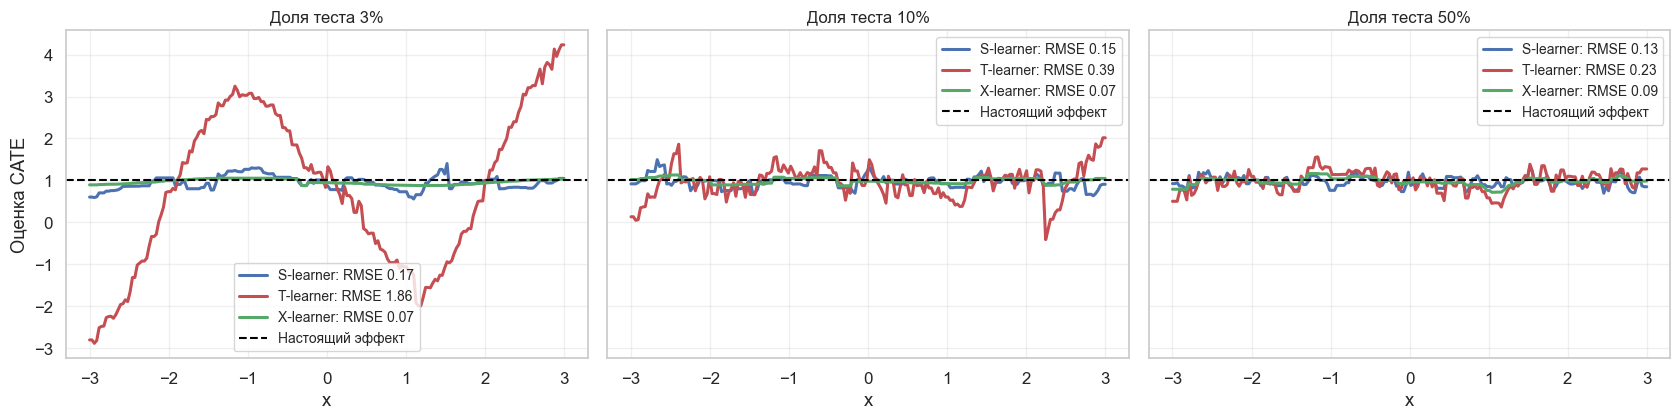

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True)
for ax, share in zip(axes, [0.03, 0.1, 0.5]):
    plot_learners(ax, share)
axes[0].set_ylabel('Оценка CATE')
plt.tight_layout()

При доле теста 3% T-learner разрушается: RMSE 1.86, потому что разность простой и сложной моделей даёт ложную нелинейность. У X-learner RMSE 0.07, а у S-learner 0.17. При доле 50% все близки: 0.09–0.23. Это то, что показывает статья: X-learner особенно полезен при неравных группах. S-learner здесь неплох, потому что воздействие достаточно сильное и не теряется.

## Debiased ML

T-, S- и X-learner дают интуитивно понятную оценку, но выглядят немного как ремесленный приём. **Double/Debiased ML**, или ортогональный ML, — это общая и строгая конструкция с хорошей асимптотической теорией. К тому же она работает и с дискретным, и с непрерывным воздействием.

В качестве примера снова рассмотрим продажи мороженого: как цена влияет на продажи. Обучающие данные наблюдательные, а значит, цены могут быть смещены. В проверочных данных цены случайны.

In [8]:
test = pd.read_csv(DATA + 'ice_cream_sales_rnd.csv')
train = pd.read_csv(DATA + 'ice_cream_sales.csv')

y = 'sales'
T = 'price'
X = ['temp', 'weekday', 'cost']
folds = KFold(n_splits=5, shuffle=True, random_state=0)
nuisance_params = dict(max_depth=3, verbose=-1, random_state=0)

print(train.shape, test.shape)
print('Средняя цена по дням недели:', train.groupby('weekday')[T].mean().round(2).to_dict())
train.head()

(10000, 5) (5000, 5)
Средняя цена по дням недели: {1: 6.82, 2: 5.82, 3: 5.84, 4: 5.86, 5: 5.89, 6: 5.82, 7: 6.8}


,temp,weekday,cost,price,sales
0,17.3,6,1.5,5.6,173
1,25.4,3,0.3,4.9,196
2,23.3,5,1.5,7.6,207
3,26.9,1,0.3,5.3,241
4,20.2,1,1.0,7.2,227


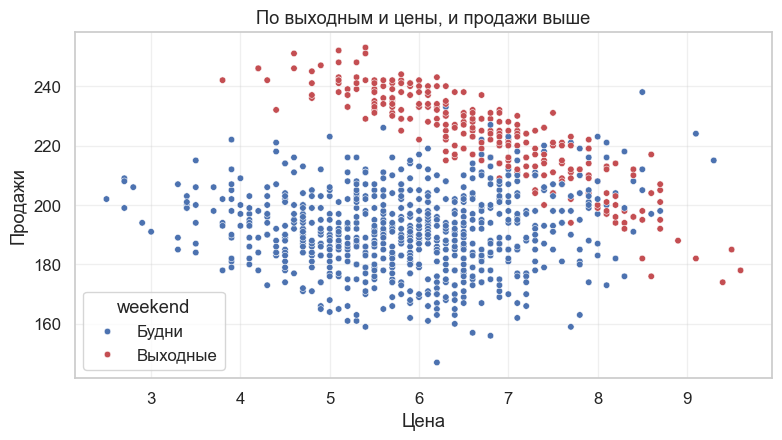

In [9]:
sample = train.sample(1000, random_state=123)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=sample.assign(weekend=sample['weekday'].isin([1, 7]).map({True: 'Выходные', False: 'Будни'})),
                x=T, y=y, hue='weekend', palette={'Выходные': RED, 'Будни': BLUE}, s=22, ax=ax)
ax.set_xlabel('Цена')
ax.set_ylabel('Продажи')
ax.set_title('По выходным и цены, и продажи выше');

Один источник смещения очевиден: цены заметно выше в выходные (дни 1 и 7), когда и продажи выше. Могут быть и другие факторы: температура и стоимость.

Можно использовать линейную модель с контролями:

$$
Sales_i = \alpha + \tau price_i + \beta_1 temp_i + \beta_2 cost_i + \pmb{\beta_3} Weekday_i + e_i
$$

где $\pmb{\beta_3}$ — вектор параметров, связанных с каждым фиктивным днём недели.

Нас интересует только $\tau$, а остальные параметры **мешающие (nuisance)**. Но их тоже нужно задать правильно, иначе оценка $\tau$ будет неверна.

Например, зависимость продаж от `temp`, вероятно, нелинейна: сначала люди идут на пляж, а в сильную жару остаются дома. Значит, модель должна быть другой:

$$
Sales_i = \alpha + \tau price_i + \beta_1 temp_i + \beta_2 temp^2_i + \beta_3 cost_i + \pmb{\beta_4} Weekday_i + e_i
$$

с квадратичным членом.

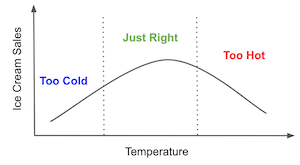

Если ковариат десятки или сотни, подобрать такую форму вручную невозможно. Здесь поможет теорема из эконометрики.

### Теорема Фриша — Во — Ловелла

Мы уже встречали её в лекциях 2.08 и 2.09, но она ключевая для ортогонального ML, поэтому повторим.

Предположим, у вас есть модель линейной регрессии с набором признаков $X_1$ и другим набором признаков $X_2$. Затем вы оцениваете параметры этой модели.

$
\hat{Y} = \hat{\beta_1} X_1 + \hat{\beta_2} X_2
$

где $X_1$ и $X_2$ — матрицы признаков. Тот же параметр $\hat{\beta_1}$ можно получить так:

1. Регрессия результата $y$ по второму набору признаков $\hat{y^*} = \hat{\gamma_1} X_2$
2. Регрессия первого набора признаков по второму $\hat{X_1} = \hat{\gamma_2} X_2$
3. Получение остатков $\tilde{X}_1 = X_1 - \hat{X_1}$ и $\tilde{y}_1 = y - \hat{y^*}$
4. Регрессия остатков результата по остаткам признаков $\tilde{y} = \hat{\beta_1} \tilde{X}_1$

Один из наборов может быть просто воздействием. Значит, мешающие параметры можно оценить отдельно: регрессируем исход на признаки, воздействие на признаки, а затем остатки исхода на остатки воздействия.

Если обозначить регрессию через $\sim$, теорема записывается так:

$
(Y - (Y \sim X)) \sim (T - (T \sim X))
$

то есть мы оцениваем $\tau$ в модели

$
Y_i - E[Y_i | X_i]
= \tau \cdot (T_i - E[T_i | X_i]) + \epsilon
$

Теорема разделяет оценку причинного и мешающих параметров, но не решает вопрос о форме мешающих функций. Здесь и нужно машинное обучение.

### Frisch-Waugh-Lovell на стероидах

Double/Debiased ML — это та же теорема, но остатки строятся с помощью ML-моделей:

$$
Y_i - \hat{M}_y(X_i) = \tau \cdot (T_i - \hat{M}_t(X_i)) + \epsilon
$$

где $\hat{M}_y(X_i)$ оценивает $E[Y|X]$, а $\hat{M}_t(X_i)$ оценивает $E[T|X]$. Гибкие модели уловят взаимодействия и нелинейность, так что параметрические предположения о связи $X$ с $Y$ и $T$ не нужны. Если нет неизмеренных конфаундеров:

1. Оцениваем $Y$ по $X$ моделью $M_y$.
2. Оцениваем $T$ по $X$ моделью $M_t$.
3. Получаем остатки $\tilde{Y} = Y - M_y(X)$ и $\tilde{T} = T - M_t(X)$.
4. Регрессируем $\tilde{Y} = \alpha + \tau \tilde{T}$.

При неоднородном эффекте $\tau$ — это не строго ATE, а средний эффект с весами, пропорциональными дисперсии $\tilde{T}$ при данном $X$.

**Почему ошибки ML не портят результат.** Статья Чернозукова и соавторов (2018) показывает, что такая оценка **ортогональна по Нейману**: небольшие ошибки в $M_y$ и $M_t$ влияют на $\tau$ только через их произведение. Поэтому оценка получается состоятельной и асимптотически нормальной, даже если сами ML-модели сходятся заметно медленнее обычного.

Но гибкость опасна переобучением:

* Если переобучена $M_y$, остаток $\tilde{Y}$ слишком мал: модель захватывает часть связи $T$ и $Y$, и оценка смещается к нулю.
* Если переобучена $M_t$, остаток $\tilde{T}$ имеет мало дисперсии. Как будто воздействие одинаково у всех, и эффект сложно оценить. То же самое бывает, если $T$ — детерминированная функция $X$: это нарушение условия перекрытия.

Решение — кросс-предсказания, то есть **остатки вне фолда**:

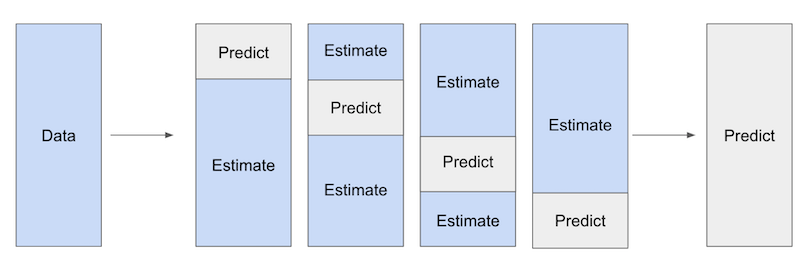

Делим данные на $K$ частей. Для части $k$ обучаем модели на остальных и считаем остатки на $k$. Даже если модель переобучится, остатки искусственно не обнулятся. В конце объединяем все части и оцениваем $\tilde{Y} = \alpha + \tau \tilde{T}$.

Начнём с модели воздействия $M_t$: она предсказывает цену по `temp`, `weekday`, `cost`. Для наглядности добавим к остаткам среднюю цену.

In [10]:
price_hat = cross_val_predict(LGBMRegressor(**nuisance_params), train[X], train[T], cv=folds)
train_pred = train.assign(price_res=train[T] - price_hat + train[T].mean())

Мы называем модель $M_t$ устраняющей смещение (debias). Остаток $\tilde{T} = T - M_t(X)$ — это вариант воздействия, из которого убрано смещение от $X$: он ортогонален $X$.

На графике ниже вместо цены стоят её остатки. Цены в выходные были выше, а теперь смещение исчезло: все дни имеют одинаковое распределение.

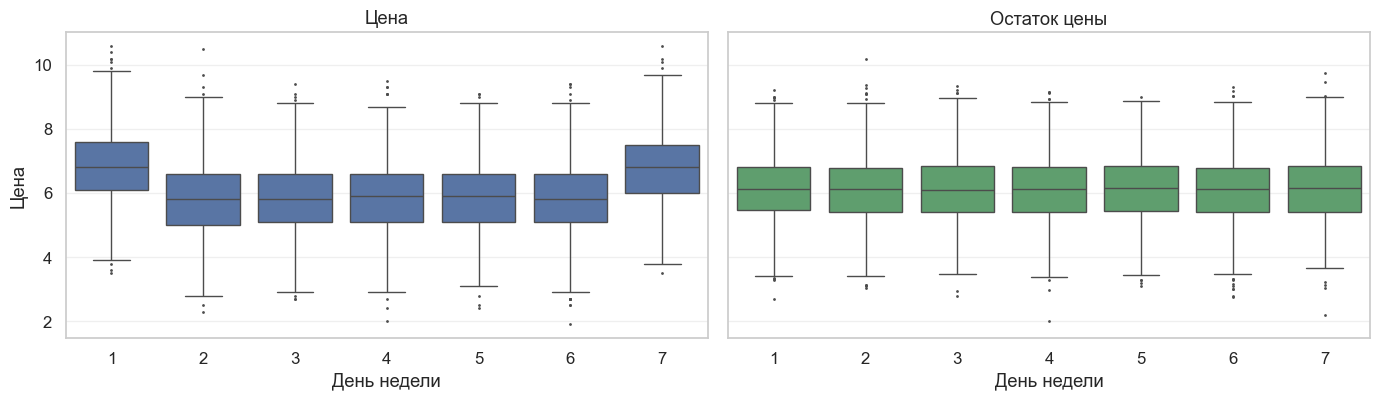

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
sns.boxplot(data=train_pred, x='weekday', y=T, ax=axes[0], color=BLUE, fliersize=1)
axes[0].set_title('Цена')
sns.boxplot(data=train_pred, x='weekday', y='price_res', ax=axes[1], color=GREEN, fliersize=1)
axes[1].set_title('Остаток цены')
axes[0].set_ylabel('Цена')
for ax in axes:
    ax.set_xlabel('День недели')
plt.tight_layout()

А роль $M_y$ — снизить дисперсию исхода. Это устраняющая шум (denoise) модель: остаток $\tilde{Y}$ освобождён от вариации, вызванной $X$, поэтому эффект виден лучше.

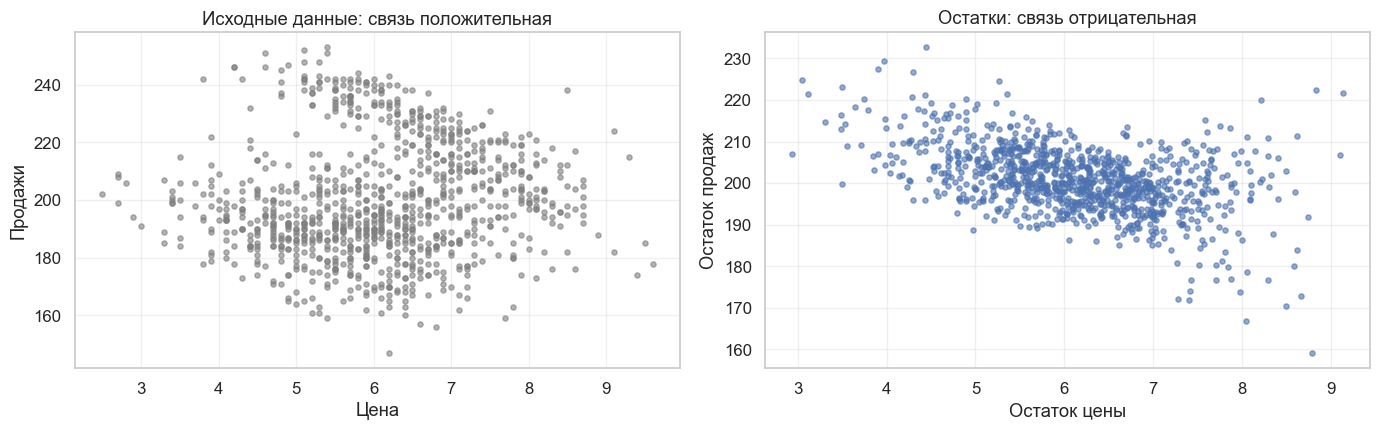

In [12]:
sales_hat = cross_val_predict(LGBMRegressor(**nuisance_params), train[X], train[y], cv=folds)
train_pred = train_pred.assign(sales_res=train[y] - sales_hat + train[y].mean())

sample = train_pred.sample(1000, random_state=123)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(sample[T], sample[y], s=14, color=GRAY, alpha=0.6)
axes[0].set_title('Исходные данные: связь положительная')
axes[0].set_xlabel('Цена')
axes[0].set_ylabel('Продажи')
axes[1].scatter(sample['price_res'], sample['sales_res'], s=14, color=BLUE, alpha=0.6)
axes[1].set_title('Остатки: связь отрицательная')
axes[1].set_xlabel('Остаток цены')
axes[1].set_ylabel('Остаток продаж')
plt.tight_layout()

Теперь отрицательная связь хорошо видна. Осталось оценить её регрессией на остатках и сравнить с наивной оценкой и с результатом на случайных ценах.

In [13]:
dml = smf.ols('sales_res ~ price_res', data=train_pred).fit(cov_type='HC1')
naive = smf.ols('sales ~ price', data=train_pred).fit(cov_type='HC1')
rct = smf.ols('sales ~ price', data=test).fit(cov_type='HC1')
rct_controls = smf.ols('sales ~ price + temp + C(weekday) + cost', data=test).fit(cov_type='HC1')

pd.DataFrame({'Оценка': ['Наивная на наблюдательных данных', 'Double ML на наблюдательных данных', 'Случайные цены', 'Случайные цены с контролями'],
              'Эффект цены': [naive.params[T], dml.params['price_res'], rct.params[T], rct_controls.params[T]],
              'SE': [naive.bse[T], dml.bse['price_res'], rct.bse[T], rct_controls.bse[T]]}).round(3)

,Оценка,Эффект цены,SE
0,Наивная на наблюдательных данных,1.229,0.143
1,Double ML на наблюдательных данных,-3.907,0.103
2,Случайные цены,-2.552,0.129
3,Случайные цены с контролями,-2.695,0.108


Наивная регрессия даёт ложный положительный эффект +1.23, потому что по выходным цены и продажи выше вместе. Double ML исправляет знак: -3.9.

Но случайные цены дают -2.6, и эта разница заслуживает внимания. Дело в том, что спрос нелинеен: на случайных ценах наклон равен -3.9 в диапазоне 3–7, -3.1 в диапазоне 4–8 и -1.1 в диапазоне 7–10. Наблюдаемые цены сосредоточены около 6: от 4.2 до 8.1 в 90% случаев, поэтому Double ML оценивает другой участок кривой, чем случайный равномерный эксперимент. Часть разницы могут объяснять и остаточные смещения. Это хорошая причина проверять оценки на случайных данных, если они есть.

Проверим роль кросс-предсказаний на симуляции. Настоящий эффект -2, цена зависит от $x$ нелинейно. Сравним прямую ML-оценку с воздействием как признаком, Double ML без кросс-предсказаний и Double ML с ними.

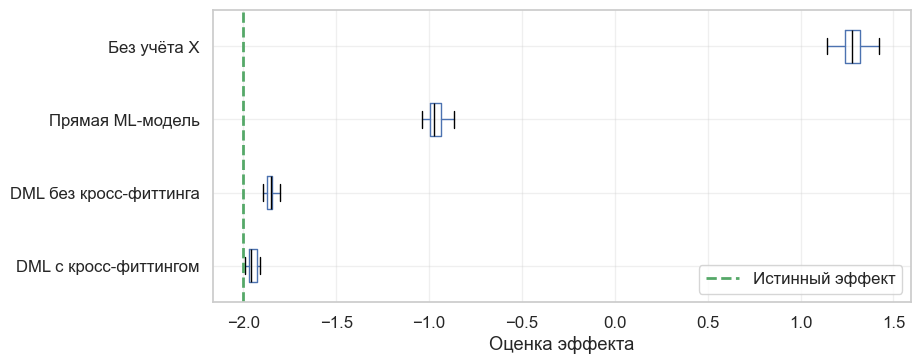

,Без учёта X,Прямая ML-модель,DML без кросс-фиттинга,DML с кросс-фиттингом
mean,1.277,-0.962,-1.861,-1.950
std,0.060,0.045,0.034,0.023


In [14]:
def simulate_dml(reps=25, n=2000, seed=11):
    """Сравнивает оценки эффекта при известном значении -2."""
    local = np.random.default_rng(seed)
    flexible = dict(n_estimators=100, num_leaves=31, min_child_samples=2, verbose=-1, random_state=0)
    regular = dict(n_estimators=100, max_depth=3, verbose=-1, random_state=0)
    rows = []
    for _ in range(reps):
        x = local.uniform(-2, 2, (n, 3))
        confounder = np.sin(2 * x[:, 0]) + x[:, 1] ** 2
        t = confounder + local.normal(0, 1, n)
        y = -2 * t + 5 * confounder + x[:, 2] + local.normal(0, 1, n)

        direct = LGBMRegressor(**regular).fit(np.column_stack([x, t]), y)
        direct_slope = np.mean(direct.predict(np.column_stack([x, t + 1])) - direct.predict(np.column_stack([x, t])))

        t_in, y_in = [v - LGBMRegressor(**flexible).fit(x, v).predict(x) for v in (t, y)]
        cv = KFold(5, shuffle=True, random_state=0)
        t_cv, y_cv = [v - cross_val_predict(LGBMRegressor(**regular), x, v, cv=cv) for v in (t, y)]
        rows.append({'Без учёта X': np.polyfit(t, y, 1)[0], 'Прямая ML-модель': direct_slope,
                     'DML без кросс-фиттинга': np.polyfit(t_in, y_in, 1)[0], 'DML с кросс-фиттингом': np.polyfit(t_cv, y_cv, 1)[0]})
    return pd.DataFrame(rows)


dml_sim = simulate_dml()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot(dml_sim.to_numpy(), vert=False, tick_labels=dml_sim.columns, showfliers=False,
           medianprops=dict(color='black'), boxprops=dict(color=BLUE), whiskerprops=dict(color=BLUE))
ax.axvline(-2, color=GREEN, ls='--', lw=2, label='Истинный эффект')
ax.invert_yaxis()
ax.set_xlabel('Оценка эффекта')
ax.legend()
plt.show()
dml_sim.agg(['mean', 'std']).round(3)

Без учёта $X$ знак вообще неверный: +1.28. Прямая ML-модель с воздействием как признаком сжимает эффект вдвое: -0.96. Это и есть смещение из-за регуляризации. Double ML без кросс-фиттинга с переобученными моделями даёт -1.86, а с кросс-фиттингом -1.95. Оставшееся смещение мало, а разброс меньше всего.

### Оценка CATE с помощью Double ML

Double ML можно использовать и для оценки неоднородности. Теперь причинный параметр зависит от ковариат:

$$
Y_i - M_y(X_i) = \tau(X_i) \cdot (T_i - M_t(X_i)) + \epsilon_i
$$

Используем те же остатки, но добавим взаимодействие остатка цены с ковариатами:

$$
\tilde{Y_i} = \alpha + \beta_1 \tilde{T_i} + \pmb{\beta}_2 \pmb{X_i} \tilde{T_i} + \epsilon_i
$$

Прогнозируем на случайных данных. Модель линейна по $\tilde{T}$, поэтому CATE можно посчитать механически как $M(\tilde{T}=1, X_i) - M(\tilde{T}=0, X_i)$.

In [15]:
final_model_cate = smf.ols('sales_res ~ price_res * (temp + C(weekday) + cost)', data=train_pred).fit()

cate_test = test.assign(cate=final_model_cate.predict(test.assign(price_res=1)) - final_model_cate.predict(test.assign(price_res=0)))
effect_test = effect_slope(test, y, T)
gain_linear = cumulative_gain(cate_test, 'cate', y, T)

Кривая кумулятивного прироста показывает, насколько хорошо модель отделяет чувствительные к цене дни от менее чувствительных.

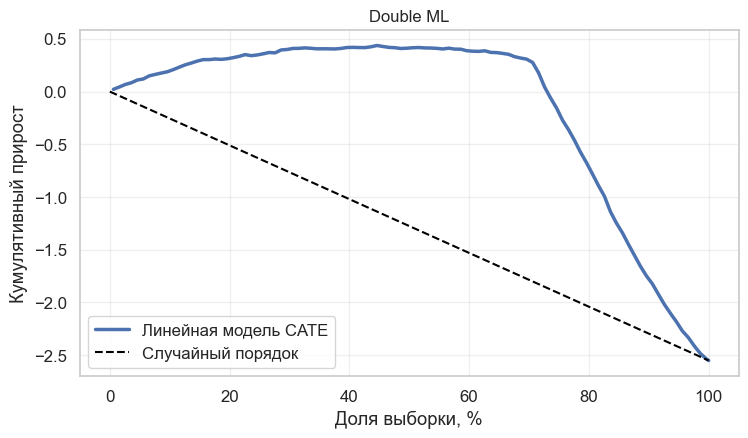

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_gain(ax, [(gain_linear, BLUE, 'Линейная модель CATE')], effect_test, 'Double ML');

Линейная итоговая модель уже работает хорошо. Но это общая процедура. Най и Вейджер (2021) называют её **R-learner**, отмечая работу Робинсона (1988) и роль остатков (residuals). Процедура определяет новую функцию потерь, которую можно минимизировать любым способом.

### Непараметрический Double ML

В модели выше эффект цены линейно зависит от признаков. Позволим ML-модели самой выучить зависимость эффекта от признаков. Начинаем как раньше: со строки остатков вне фолда.

In [17]:
train_pred = train.assign(price_res=train[T] - price_hat, sales_res=train[y] - sales_hat)

Double ML моделирует данные так:

$$
Y_i = \hat{M}_y(X_i) + \tau(X_i) \big(T_i - \hat{M}_t(X_i)\big) + \hat{\epsilon}_i
$$

Выделим ошибку:

$$
\hat{\epsilon}_i = \big(Y_i - \hat{M}_y(X_i)\big) - \tau(X_i) \big(T_i - \hat{M}_t(X_i)\big)
$$

Это **причинная функция потерь**: минимизируя её квадрат, мы оцениваем $\tau(X_i)$. Она называется **R-Loss**:

$$
\hat{L}_n(\tau(x)) = \frac{1}{n} \sum^n_{i=1}\bigg(\big(Y_i - \hat{M}_y(X_i)\big) - \tau(X_i) \big(T_i - \hat{M}_t(X_i)\big)\bigg)^2 = \frac{1}{n} \sum^n_{i=1}\bigg( \tilde{Y}_i - \tau(X_i) \tilde{T}_i \bigg)^2
$$

Вынесем $\tilde{T}_i$ за скобки:

$$
\hat{L}_n(\tau(x)) = \frac{1}{n} \sum^n_{i=1} \tilde{T}_i^2 \left(\frac{\tilde{Y}_i}{\tilde{T}_i} - \tau(X_i)\right)^2
$$

Минимизация — это обычная регрессия цели $\tilde{Y}_i/\tilde{T}_i$ с весами $\tilde{T}_i^2$. Это та же трансформация цели, что в лекции 2.10, но с весами. Алгоритм:

1. Создаём веса $\tilde{T}_i^2$.
2. Создаём цель $\tilde{Y}_i / \tilde{T}_i$.
3. Обучаем любую регрессию на цель с этими весами, используя только $X$.

In [18]:
weights = train_pred['price_res'] ** 2
y_star = train_pred['sales_res'] / train_pred['price_res']

model_final = LGBMRegressor(**nuisance_params).fit(train[X], y_star, sample_weight=weights)

cate_test_non_param = test.assign(cate=model_final.predict(test[X]))
gain_non_param = cumulative_gain(cate_test_non_param, 'cate', y, T)

Готовая прогностическая модель оценивает CATE. Сравним её с линейной версией на случайных данных.

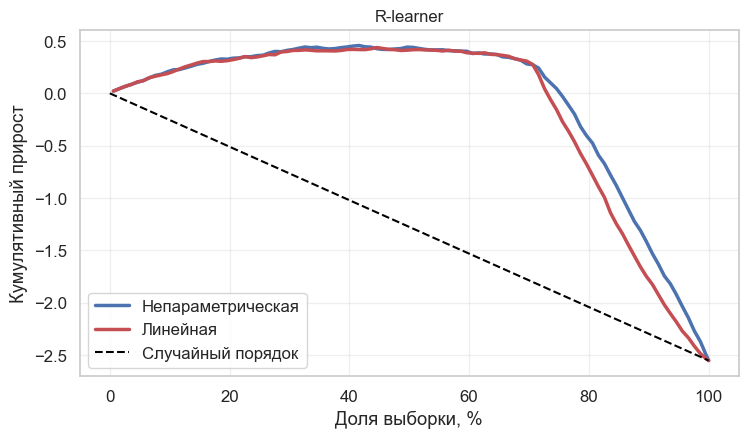

Площадь над случайным порядком, линейная:          0.448
Площадь над случайным порядком, непараметрическая: 0.479


In [19]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_gain(ax, [(gain_non_param, BLUE, 'Непараметрическая'), (gain_linear, RED, 'Линейная')], effect_test, 'R-learner')
plt.show()
print('Площадь над случайным порядком, линейная:         ', round(gain_area(gain_linear, effect_test), 3))
print('Площадь над случайным порядком, непараметрическая:', round(gain_area(gain_non_param, effect_test), 3))

Непараметрическая версия чуть лучше линейной: площадь 0.48 против 0.45. Главное преимущество в том, что форму зависимости эффекта от признаков не нужно задавать вручную.

### Что значит «непараметрический»

Распространённое заблуждение: непараметрическая модель будто бы находит нелинейный эффект воздействия. Но в ней остаётся предположение

$$
\tilde{Y}_i = \tau(X_i) \tilde{T}_i + e_i
$$

То есть **при данном $X$ воздействие влияет на исход линейно**. Непараметрической становится зависимость эффекта от $X$, а не от $T$. На практике $\tau(X)$ — это средний наклон $Y$ по $T$ при данном $X$. Если при фиксированном $X$ воздействие меняется мало, наклон близок к производной в точке $E[T|X]$. Это локально-линейное приближение к нелинейной функции.

Проверим. Пусть продажи зависят от скидки как

$$
Sales_i = 20 + 10\sqrt{Discount_i} + e_i
$$

Эффект — это производная, и она падает с ростом скидки:

$$
\dfrac{\partial Sales_i}{\partial Discount_i} = \dfrac{5}{\sqrt{Discount_i}}
$$

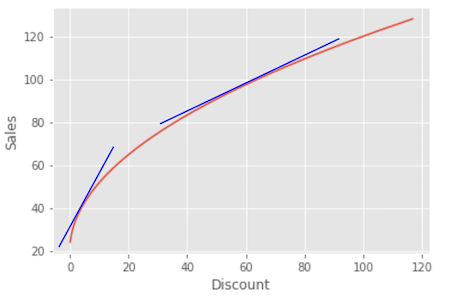

Пусть средний размер скидки зависит от признака $x$: $Discount_i = 5 + 40 x_i + \varepsilon_i$. Тогда разные $x$ соответствуют разным участкам кривой. Сравним оценку $\tau(x)$ с производной в точке $E[T|x]$.

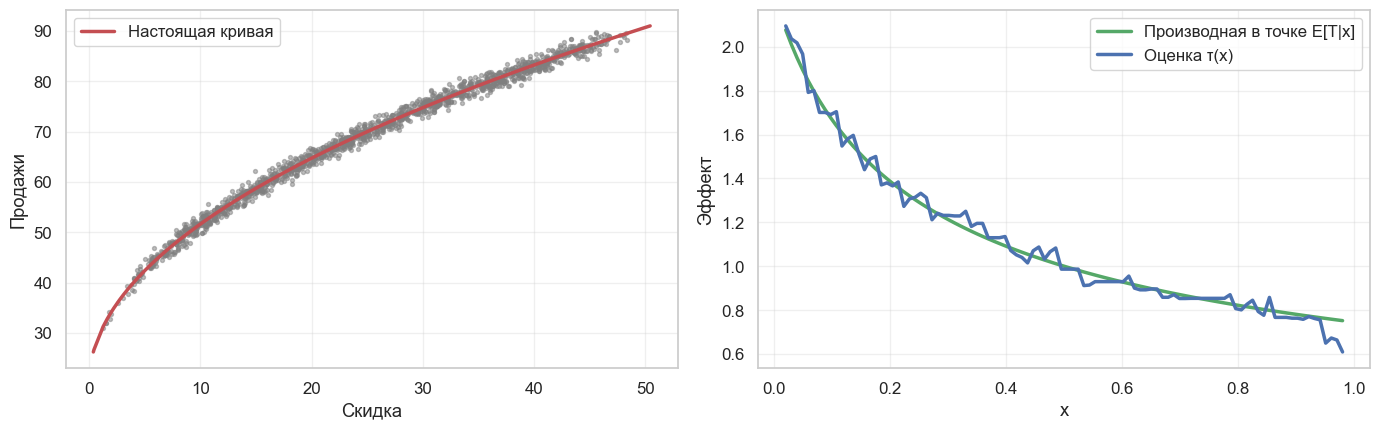

In [20]:
n = 10_000
x_sim = rng.uniform(0, 1, n)
discount = np.clip(5 + 40 * x_sim + rng.normal(0, 2, n), 0.1, None)
sales_sim = rng.normal(20 + 10 * np.sqrt(discount), 1)

x_matrix = x_sim.reshape(-1, 1)
discount_res = discount - cross_val_predict(LGBMRegressor(**nuisance_params), x_matrix, discount, cv=folds)
sales_sim_res = sales_sim - cross_val_predict(LGBMRegressor(**nuisance_params), x_matrix, sales_sim, cv=folds)

non_param = LGBMRegressor(**nuisance_params).fit(x_matrix, sales_sim_res / discount_res, sample_weight=discount_res ** 2)

grid = np.linspace(0.02, 0.98, 100)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(discount[:1500], sales_sim[:1500], s=8, color=GRAY, alpha=0.5)
axes[0].plot(np.sort(discount), 20 + 10 * np.sqrt(np.sort(discount)), color=RED, lw=2.5, label='Настоящая кривая')
axes[0].set_xlabel('Скидка')
axes[0].set_ylabel('Продажи')
axes[0].legend()

axes[1].plot(grid, 5 / np.sqrt(5 + 40 * grid), color=GREEN, lw=2.5, label='Производная в точке E[T|x]')
axes[1].plot(grid, non_param.predict(grid.reshape(-1, 1)), color=BLUE, lw=2.5, label='Оценка τ(x)')
axes[1].set_xlabel('x')
axes[1].set_ylabel('Эффект')
axes[1].legend()
plt.tight_layout()

Оценка хорошо совпадает с производной: у $x$ с маленькой скидкой большой эффект, у $x$ с большой маленький. Важно, что это получается из-за того, что в данных $X$ задаёт уровень воздействия.

В исходной лекции здесь иначе: признаков не было, и в роли признака выступал сам `discount`. Но тогда цель $\tilde{Y}/\tilde{T}$ с весами $\tilde{T}^2$ при данном $T$ равна **наклону хорды** от средней точки к точке $T$: $(g(T) - \bar{g}) / (T - \bar{T})$, а не наклону касательной. Проверим это.

In [21]:
discount_only = rng.gamma(2, 10, n)
sales_only = rng.normal(20 + 10 * np.sqrt(discount_only), 1)
residual_d, residual_s = discount_only - discount_only.mean(), sales_only - sales_only.mean()
chord_model = LGBMRegressor(**nuisance_params).fit(discount_only.reshape(-1, 1), residual_s / residual_d, sample_weight=residual_d ** 2)

levels = np.array([1, 5, 10, 40, 60, 80.0])
mean_curve = (20 + 10 * np.sqrt(discount_only)).mean()
pd.DataFrame({'Скидка': levels, 'Оценка модели': chord_model.predict(levels.reshape(-1, 1)),
              'Касательная': 5 / np.sqrt(levels),
              'Хорда от среднего': (20 + 10 * np.sqrt(levels) - mean_curve) / (levels - discount_only.mean())}).round(3)

,Скидка,Оценка модели,Касательная,Хорда от среднего
0,1.0,1.702,5.000,1.687
1,5.0,1.322,2.236,1.310
2,10.0,1.038,1.581,1.036
3,40.0,1.067,0.791,1.063
4,60.0,0.883,0.645,0.887
5,80.0,0.756,0.559,0.791


Оценка совпадает с хордой, а не с касательной: при скидке 1 это 1.70, хотя производная равна 5. Поэтому утверждение «модель находит касательную» верно только тогда, когда $X$ задаёт уровень воздействия, как в нашем первом примере, и $\tau$ зависит от $X$, а не от самого $T$.

Это важно на практике. Пусть у клиента со скидкой 5 эффект равен 2: одна единица скидки даёт 2 продажи. Кажется, что можно дать ему скидку 20. Но эффект 2 верен только около текущего уровня: при большей скидке он упадёт, и решение может стать убыточным. Поэтому **экстраполировать эффект на другой уровень воздействия опасно**.

### Контрфактические прогнозы

Последняя идея менее строгая. Источник называет её «ненаучным» Double ML.

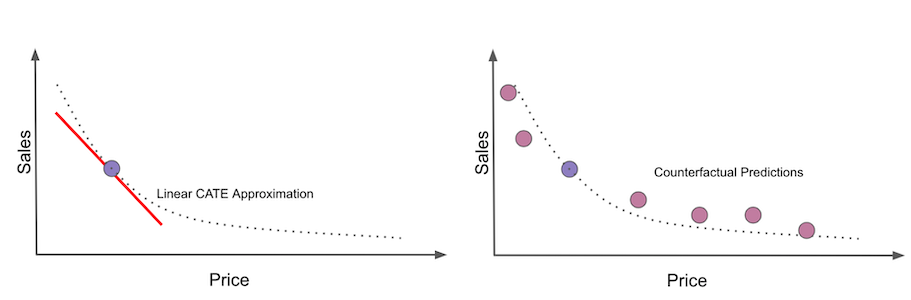

CATE — это наклон функции исхода в точке. Контрфактический прогноз — попытка восстановить всю кривую: что было бы при другом уровне воздействия. Мы будем экстраполировать кривую из одной точки, поэтому такое занятие рискованно.

Поместим воздействие внутрь функции эффекта, чтобы эффект мог меняться вместе с ним:

$$
\tilde{Y}_i = \tau(X_i, \tilde{T}_i) + e_i
$$

Обучаем ML-модель предсказывать $\tilde{Y}$ по $\tilde{T}$ и $X$. Для прогноза при цене $t$ считаем $\tilde{t} = t - M_t(X)$ и подставляем в модель. Поскольку нужны сами модели первого шага, реализуем кросс-предсказание вручную. У LightGBM есть удобная опция: можно запретить прогнозу расти с ценой с помощью монотонного ограничения.

In [22]:
def cv_estimate(data, model_params, features_list, target):
    """Возвращает прогнозы вне фолда и модели, которые их сделали."""
    prediction = pd.Series(np.nan, index=data.index)
    models = []
    for train_idx, test_idx in folds.split(data):
        fitted = LGBMRegressor(**model_params).fit(data[features_list].iloc[train_idx], data[target].iloc[train_idx])
        prediction.iloc[test_idx] = fitted.predict(data[features_list].iloc[test_idx])
        models.append(fitted)
    return prediction, models


def ensemble_predict(df, models, features_list):
    return np.mean([m.predict(df[features_list]) for m in models], axis=0)


y_hat, models_y = cv_estimate(train, nuisance_params, X, y)
t_hat, models_t = cv_estimate(train, nuisance_params, X, T)
y_res, t_res = train[y] - y_hat, train[T] - t_hat

monotone = [-1 if col == T else 0 for col in X + [T]]
model_counterfactual = LGBMRegressor(max_depth=3, monotone_constraints=monotone, verbose=-1, random_state=0).fit(train[X].assign(**{T: t_res}), y_res)


def counterfactual_sales(data, prices):
    """Прогнозирует продажи каждого дня при каждой цене из списка."""
    grid = (data.rename(columns={T: 'factual_price'}).reset_index()
            .merge(pd.DataFrame({T: prices}), how='cross'))
    residual = grid[T] - ensemble_predict(grid, models_t, X)
    grid[f'{y}_pred'] = ensemble_predict(grid, models_y, X) + model_counterfactual.predict(grid[X].assign(**{T: residual}))
    return grid


pred_test = counterfactual_sales(test, np.linspace(3, 10, 9))
pred_test.query('index == 0')[['temp', 'weekday', 'cost', 'factual_price', 'sales', T, 'sales_pred']].round(2)

,temp,weekday,cost,factual_price,sales,price,sales_pred
0,25.8,1,0.3,7,230,3.00,253.67
1,25.8,1,0.3,7,230,3.88,249.43
2,25.8,1,0.3,7,230,4.75,244.10
3,25.8,1,0.3,7,230,5.62,235.84
4,25.8,1,0.3,7,230,6.50,227.92
5,25.8,1,0.3,7,230,7.38,218.23
6,25.8,1,0.3,7,230,8.25,213.44
7,25.8,1,0.3,7,230,9.12,209.87
8,25.8,1,0.3,7,230,10.00,209.87


Для каждого дня мы получили кривую спроса. Начнём все кривые с одного уровня, чтобы увидеть различия в чувствительности.

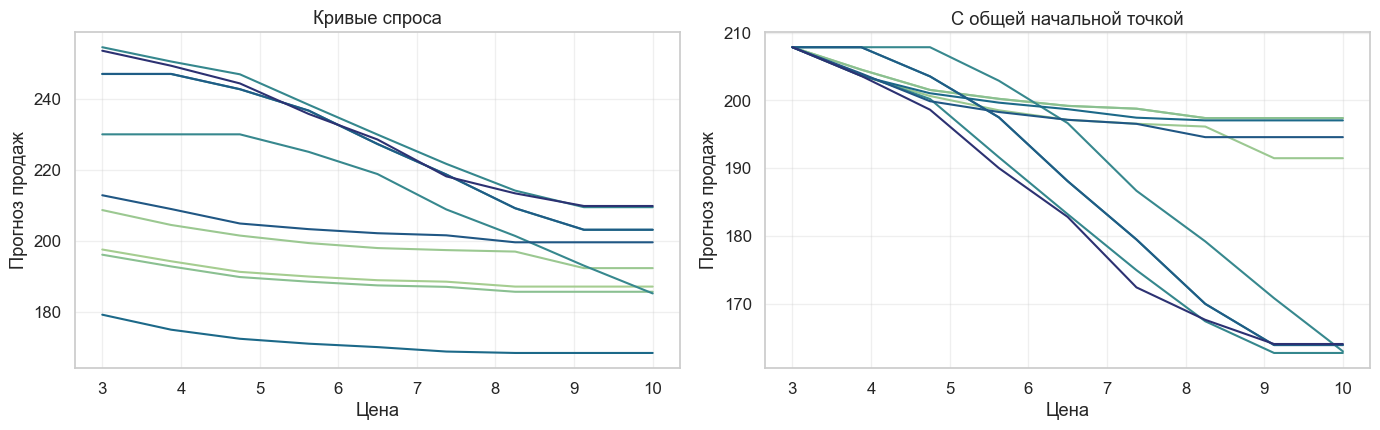

In [23]:
sample_ids = pd.Series(pred_test['index'].unique()).sample(10, random_state=1)
curves_sample = (pred_test.query('index in @sample_ids')
                 .assign(start=lambda d: d.groupby('index')['sales_pred'].transform('max'),
                         shifted=lambda d: d['sales_pred'] - d['start'] + d['sales_pred'].mean()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, column, title in [(axes[0], 'sales_pred', 'Кривые спроса'), (axes[1], 'shifted', 'С общей начальной точкой')]:
    sns.lineplot(data=curves_sample, x=T, y=column, hue='index', palette='crest', legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Цена')
    ax.set_ylabel('Прогноз продаж')
plt.tight_layout()

У некоторых дней продажи падают сильно, у других слабо.

### Проверка на случайных ценах

В проверочных данных цены случайны, поэтому средний спрос при каждой цене — это настоящая причинная кривая. Сравним её со средним контрфактическим прогнозом.

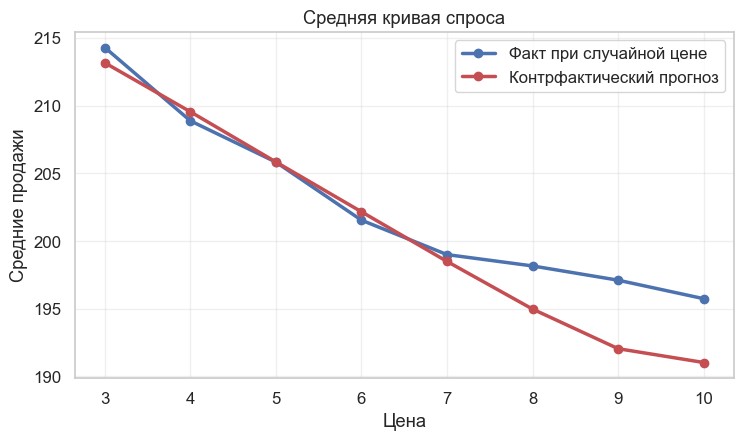

Средняя абсолютная ошибка: 1.99
Наклон факта:    -2.552
Наклон прогноза: -3.319


In [24]:
actual_curve = test.groupby(T)[y].mean()
predicted_curve = counterfactual_sales(test, actual_curve.index.to_numpy().astype(float)).groupby(T)['sales_pred'].mean()

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(actual_curve.index, actual_curve, 'o-', color=BLUE, lw=2.5, label='Факт при случайной цене')
ax.plot(predicted_curve.index, predicted_curve, 'o-', color=RED, lw=2.5, label='Контрфактический прогноз')
ax.set_xlabel('Цена')
ax.set_ylabel('Средние продажи')
ax.set_title('Средняя кривая спроса')
ax.legend()
plt.show()
print('Средняя абсолютная ошибка:', round((predicted_curve - actual_curve).abs().mean(), 2))
print('Наклон факта:   ', round(np.polyfit(actual_curve.index, actual_curve, 1)[0], 3))
print('Наклон прогноза:', round(np.polyfit(predicted_curve.index, predicted_curve, 1)[0], 3))

До цены 7 средний прогноз почти совпадает с фактом. Выше модель переоценивает падение: при цене 10 прогноз 191 при факте 196. Наблюдаемые цены редко бывают высокими, поэтому там модель экстраполирует. Наклон -3.3 при фактическом -2.6, средняя ошибка 2 единицы продаж. Без случайных цен мы бы об этом не узнали.

### Ограничения

Этот подход хрупок. Итоговая модель регуляризована, и это может сдвигать эффект к нулю. Кроме того, деревья плохо дают гладкие прогнозы, отсюда ступеньки на графиках, и плохо экстраполируют. Посмотрим на цены до 30, которых нет в данных.

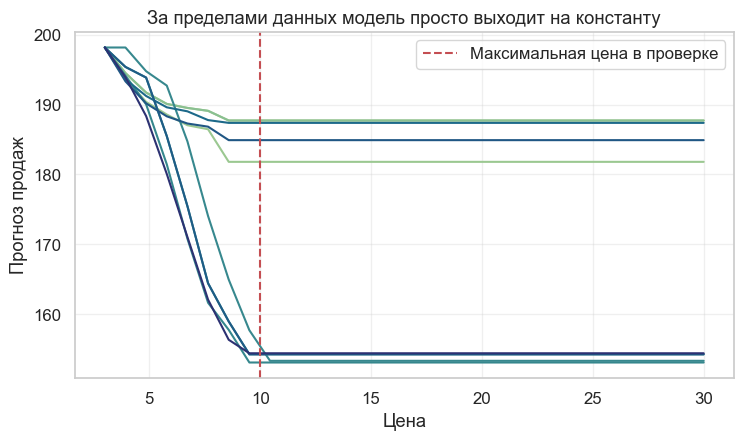

In [25]:
extrapolated = counterfactual_sales(test, np.linspace(3, 30, 30))
sample_curves = (extrapolated.query('index in @sample_ids')
                 .assign(shifted=lambda d: d['sales_pred'] - d.groupby('index')['sales_pred'].transform('max') + d['sales_pred'].mean()))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.lineplot(data=sample_curves, x=T, y='shifted', hue='index', palette='crest', legend=False, ax=ax)
ax.axvline(test[T].max(), color=RED, ls='--', label='Максимальная цена в проверке')
ax.set_xlabel('Цена')
ax.set_ylabel('Прогноз продаж')
ax.set_title('За пределами данных модель просто выходит на константу')
ax.legend();

За пределами наблюдаемых цен кривые просто становятся плоскими: это особенность деревьев, а не свойство спроса. Если регуляризовать слишком сильно, эффект сожмётся к нулю. Выбор алгоритма переносит все его ограничения на контрфактические прогнозы. Поэтому подход можно использовать только с проверкой на случайных данных.

## Заключение

| Метод | Идея | Сильная сторона | Слабое место |
| :--- | :--- | :--- | :--- |
| S-learner | Одна модель, воздействие как признак | Прост, работает с непрерывным $T$ | Регуляризация сжимает эффект к нулю |
| T-learner | Модель на каждое значение $T$ | Не теряет воздействие | Ломается при неравных группах |
| X-learner | Импутация эффектов и взвешивание | Хорош при малой тестовой группе | Только дискретное $T$ |
| Double ML | Регрессия остатков на остатки | Строгая теория, есть интервалы | Эффект линеен по $T$ при данном $X$ |
| R-learner | Минимизация R-Loss любой моделью | Гибкая зависимость эффекта от $X$ | Эффект всё ещё локален |

Главное из лекции:

* ни один из этих методов не устраняет неизмеренные конфаундеры;
* качество CATE проверяют на случайных данных, а не на смещённой обучающей выборке;
* Double ML опирается на ортогональность и кросс-предсказания;
* непараметрический означает гибкую зависимость эффекта от $X$, а не нелинейность по $T$;
* нельзя экстраполировать эффект на другой уровень воздействия без проверки.